In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

# Load the dataset
wine = load_wine(as_frame=True)

df = wine.frame

In [3]:
# Separate features and target
X = df.drop(columns = "target")
y = df["target"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
# Standardize: each feature gets mean 0 and standard deviation 1
mlp_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(5,4), max_iter=500, random_state=42)
)

mlp_pipeline.fit(x_train,y_train)

acc = mlp_pipeline.score(x_test, y_test)
print(acc)

1.0


## 3. Experiment with network architecture

  architecture  parameters  train_accuracy  test_accuracy
0         (5,)          88             1.0       0.972222
1        (10,)         173             1.0       0.972222
2        (20,)         343             1.0       1.000000
3        (50,)         853             1.0       1.000000
4     (20, 10)         523             1.0       1.000000
5     (50, 20)        1783             1.0       1.000000


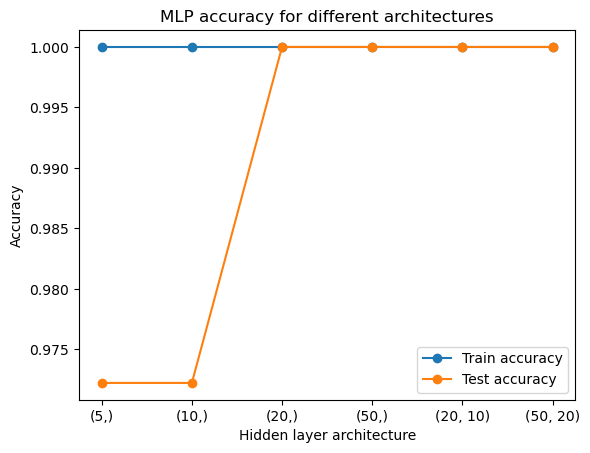

In [8]:
architectures = [(5,), (10,), (20,), (50,), (20, 10), (50, 20)]
results = []

for arch in architectures:
    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes = arch, max_iter = 1000, random_state = 42)
    )
    model.fit(x_train, y_train)
    n_params = sum(w.size for w in model[-1].coefs_) + sum(b.size for b in model[-1].intercepts_)
    results.append({
        "architecture": str(arch),
        "parameters": n_params,
        "train_accuracy": accuracy_score(y_train, model.predict(x_train)),
        "test_accuracy": accuracy_score(y_test, model.predict(x_test)),
    })

arch_df = pd.DataFrame(results)
print(arch_df)

# Plot
labels = [str(a) for a in architectures]
plt.plot(labels, arch_df["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(labels, arch_df["test_accuracy"], marker="o", label="Test accuracy")
plt.xlabel("Hidden layer architecture")
plt.ylabel("Accuracy")
plt.title("MLP accuracy for different architectures")
plt.legend()
plt.show()

Questions:
1. 